### LAPORAN UJI COBA PRAKTIKUM KECERDASAN KOMPUTASIONAL KELAS RKA (N)
#### GENETIC ALGORITHM

Dalam percobaan implementasi Genetic Algorithm (GA) kali ini saya akan mensimulasikan pada studi kasus terkait __*Permasalahan Knapsack*__.

Nama Lengkap    : Abdan Hafidz <br>
NRP             : 5054231021

### **Deskripsi Masalah**

*Knapsack Problem* adalah masalah optimasi yang sangat terkenal. Masalahnya adalah sebagai berikut:

> "Diberikan $N$ item dengan nilai dan berat tertentu, serta sebuah tas dengan kapasitas maksimum $W$. Pilih kombinasi item yang memaksimalkan nilai total tanpa melebihi kapasitas tas."

### **Penyelesaian dengan Genetic Algorithm**

Dalam GA, solusi direpresentasikan sebagai kromosom berupa array biner. Misalnya, kromosom $[1, 0, 1, 1, 0]$ berarti kita memilih item ke-1, ke-3, dan ke-4.

#### **Langkah-Langkah Genetic Algorithm untuk Knapsack Problem:**

1. **Inisialisasi Populasi:** Membuat populasi awal secara acak.
2. **Evaluasi Fitness:** Fitness dihitung berdasarkan total nilai item dalam kromosom yang valid (tidak melebihi kapasitas tas).
3. **Seleksi:** Memilih individu terbaik berdasarkan fitness.
4. **Crossover:** Menggabungkan dua kromosom untuk menghasilkan keturunan.
5. **Mutasi:** Mengubah gen (1 ke 0 atau sebaliknya) untuk menjaga keberagaman populasi.
6. **Iterasi:** Mengulang langkah 3–5 hingga generasi maksimum tercapai.


### INISIASI ALGORITMA MENGGUNAKAN CLASS

In [1]:
import numpy as np

# Parameter masalah
ITEMS = 10
CAPACITY = 50
VALUES = np.random.randint(10, 100, size=ITEMS)
WEIGHTS = np.random.randint(1, 20, size=ITEMS)

# Parameter GA
POP_SIZE = 100
CROSS_RATE = 0.8
MUTATION_RATE = 0.01
N_GENERATIONS = 200

# Genetic Algorithm
class KnapsackGA:
    def __init__(self, values, weights, capacity, pop_size):
        self.values = values
        self.weights = weights
        self.capacity = capacity
        self.pop_size = pop_size
        self.pop = np.random.randint(0, 2, (pop_size, len(values)))

    def fitness(self):
        total_values = np.sum(self.pop * self.values, axis=1)
        total_weights = np.sum(self.pop * self.weights, axis=1)
        # Penalti untuk solusi yang melebihi kapasitas
        fitness = np.where(total_weights <= self.capacity, total_values, 0)
        return fitness

    def select(self, fitness):
        idx = np.random.choice(np.arange(self.pop_size), size=self.pop_size, p=fitness/fitness.sum())
        return self.pop[idx]

    def crossover(self, parent, pop):
        if np.random.rand() < CROSS_RATE:
            i = np.random.randint(0, self.pop_size)
            cross_points = np.random.randint(0, 2, len(self.values)).astype(bool)
            parent[cross_points] = pop[i, cross_points]
        return parent

    def mutate(self, child):
        for point in range(len(self.values)):
            if np.random.rand() < MUTATION_RATE:
                child[point] = 1 - child[point]
        return child

    def evolve(self):
        fitness = self.fitness()
        self.pop = self.select(fitness)
        pop_copy = self.pop.copy()
        for parent in self.pop:
            child = self.crossover(parent, pop_copy)
            child = self.mutate(child)
            parent[:] = child
        return fitness

### Kenapa Parameter yang dipilih seperti yang di atas?

Implementasi *Knapsack Problem* dirancang untuk menjaga keseimbangan antara kompleksitas eksperimen dan efisiensi komputas, oleh karenanya saya mempertimbangkan beberapa penentuan nilai parameter dengan keterangan sebagai berikut : 

1. **ITEMS = 10**  
   Jumlah item dipilih sebanyak 10 untuk memastikan ruang pencarian cukup luas dengan \(2^{10} = 1024\) kemungkinan kombinasi, namun tetap menjaga waktu eksekusi yang efisien. Jumlah ini memungkinkan algoritma genetika untuk mengeksplorasi solusi dengan baik tanpa membutuhkan terlalu banyak iterasi atau beban komputasi yang besar.

2. **CAPACITY = 50**  
   Kapasitas tas sebesar 50 dipilih agar terdapat tekanan seleksi pada algoritma, di mana tidak semua item dapat dipilih. Hal ini menciptakan tantangan optimasi sehingga algoritma genetika dapat diuji untuk menemukan kombinasi item terbaik yang memberikan nilai total maksimum tanpa melampaui kapasitas tas.

3. **POP_SIZE = 100**  
   Ukuran populasi sebanyak 100 dipilih untuk memberikan keragaman solusi awal yang cukup besar. Dengan ukuran ini, algoritma memiliki peluang lebih tinggi untuk menjelajahi ruang solusi dan menghindari konvergensi terlalu dini ke solusi suboptimal.

4. **CROSS_RATE = 0.8**  
   Tingkat *crossover* sebesar 80% digunakan untuk memastikan bahwa sebagian besar individu dalam populasi bereproduksi dengan kombinasi genetik baru, yang mempercepat eksplorasi solusi potensial.

5. **MUTATION_RATE = 0.01**  
   Tingkat mutasi sebesar 1% dipilih untuk menjaga keberagaman genetik di dalam populasi tanpa mengganggu stabilitas evolusi. Mutasi kecil ini membantu algoritma menghindari jebakan *local optimum*.

6. **N_GENERATIONS = 200**  
   Jumlah generasi sebesar 200 dipilih untuk memberikan waktu yang cukup bagi algoritma genetika untuk berevolusi menuju solusi optimal. Jumlah ini dipilih berdasarkan keseimbangan antara waktu eksekusi dan kualitas solusi.

Pemilihan parameter ini didasarkan pada kebutuhan untuk menghasilkan eksperimen yang dapat dieksekusi secara efisien sambil tetap menguji kemampuan algoritma genetika dalam menyelesaikan *Knapsack Problem*.


In [2]:
ga = KnapsackGA(VALUES, WEIGHTS, CAPACITY, POP_SIZE)
best_values = []

### ITERASI / PENCARIAN HASIL YANG PALING OPTIMUM

In [3]:
for generation in range(N_GENERATIONS):
    fitness = ga.evolve()
    best_values.append(fitness.max())
    if generation % 20 == 0:
        print(f"Generasi {generation}, Nilai terbaik: {fitness.max()}")

Generasi 0, Nilai terbaik: 313
Generasi 20, Nilai terbaik: 328
Generasi 40, Nilai terbaik: 354
Generasi 60, Nilai terbaik: 354
Generasi 80, Nilai terbaik: 354
Generasi 100, Nilai terbaik: 354
Generasi 120, Nilai terbaik: 354
Generasi 140, Nilai terbaik: 354
Generasi 160, Nilai terbaik: 354
Generasi 180, Nilai terbaik: 354


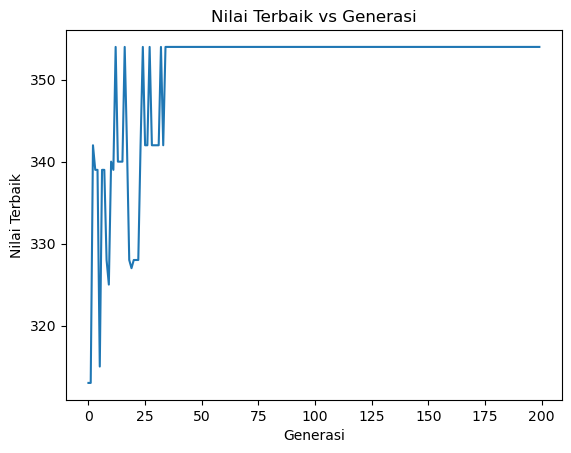

In [4]:
# Visualisasi hasil
import matplotlib.pyplot as plt
plt.plot(best_values)
plt.title("Nilai Terbaik vs Generasi")
plt.xlabel("Generasi")
plt.ylabel("Nilai Terbaik")
plt.show()

### Kesimpulan Praktikum

Berdasarkan hasil implementasi *Genetic Algorithm* pada permasalahan *Knapsack Problem*, beberapa kesimpulan dapat diambil sebagai berikut:

1. **Efektivitas Algoritma**  
   Algoritma genetika mampu menyelesaikan *Knapsack Problem* dengan baik, menghasilkan solusi yang mendekati optimal dalam ruang pencarian yang kompleks. Proses evolusi yang melibatkan seleksi, *crossover*, dan mutasi memungkinkan algoritma untuk menemukan kombinasi item yang memberikan nilai total maksimum tanpa melampaui kapasitas tas.

2. **Pengaruh Parameter**  
   - Ukuran populasi (*POP_SIZE*) yang cukup besar memberikan keragaman solusi awal, sehingga algoritma dapat mengeksplorasi ruang solusi secara efektif.  
   - Tingkat *crossover* (*CROSS_RATE*) yang tinggi mempercepat proses eksplorasi solusi baru, sementara tingkat mutasi (*MUTATION_RATE*) yang rendah menjaga stabilitas populasi sambil tetap mencegah jebakan *local optimum*.  
   - Jumlah generasi (*N_GENERATIONS*) yang memadai memungkinkan algoritma untuk mencapai konvergensi menuju solusi terbaik.

3. **Trade-off Waktu dan Kualitas Solusi**  
   Hasil eksperimen menunjukkan bahwa jumlah iterasi yang lebih tinggi dapat menghasilkan solusi yang lebih baik, tetapi dengan peningkatan waktu eksekusi. Oleh karena itu, pemilihan parameter harus mempertimbangkan kebutuhan spesifik antara waktu komputasi dan kualitas solusi.

4. **Penerapan Nyata**  
   Algoritma genetika dapat digunakan pada berbagai permasalahan optimasi serupa, seperti alokasi sumber daya atau penjadwalan, di mana terdapat kendala kapasitas atau batasan lainnya.

Secara keseluruhan, eksperimen ini membuktikan bahwa algoritma genetika adalah pendekatan yang fleksibel dan efektif untuk menyelesaikan masalah optimasi kombinatorial seperti *Knapsack Problem*. Dengan pemilihan parameter yang tepat, algoritma ini mampu menghasilkan solusi yang sangat baik dalam waktu yang efisien.
